[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/AtomicPhys/blob/main/Atomic_py/atomicphys_atomlight.ipynb)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy
from sympy import *

# Взаємодія атома та ЕМП

$\newcommand{\ket}[1]{\left.\left\vert\, #1\,\right. \right \rangle}$
$\newcommand{\bra}[1]{\left. \langle \, #1\, \right\vert}$
$\newcommand{\braket}[2]{\langle \,#1 \vert #2 \, \rangle}$
$\newcommand{\av}[3]{\left\langle \,#1 \left \vert\, #2 \,\right\vert #3 \,\right \rangle}$

## Випромінювання і поглинання світла квантовою системою. Спонтанне і вимушене випромінювання.
<!--  -->
Проблема взаємодії атома і ЕМП є центральною задачею з якої виникла квантова теорія - проблема чорного/теплового випромінювання. Хоча наведені нижче результати будуть суто класичними, тим не менше, по суті вони зберігаються і у квантовомеханчіному підході. Єдиною відмінністю є дискретизація частот у відповідності до спектру атома $\omega \to \omega_{m\to n} = \frac{E_{m}-E_{n}}{\hbar}$.

З т.з. класичної електродинаміки атом складається із заряджених частинок які рухаються з прискоренням. В рамках простої моделі атом можна вважати диполем а віповідне випромінювання дипольним. Для повноти наведемо відповідні результати з електродинаміки. 
Рівняння Максвелла за умови виконання калібрування Лоренца (Lorenz gauge):
<!--  -->
\begin{equation}
\frac{1}{c}\,\frac{\partial \varphi}{\partial t} + {\rm div} \,\mathbf{A} = 0
\label{loretzgauge}
\end{equation}
<!--  -->
виглядають таким чином:
<!--  -->
\begin{equation}
\square\, \varphi = 4\pi\,\rho\,,\,\,\,\,
\square\, \mathbf{A} = \frac{4\pi}{c}\, \mathbf{j}\\
\square = \frac{1}{c^2}\frac{\partial^2 }{\partial t^2} - \Delta\,\,\,\, - \text{
d'Alembert operator} 
\end{equation}
<!--  -->
Якщо рух зарядів відбувається у обмеженій області, то використовуючи відомий вираз для функції Гріна оператора Лапласа, можемо записати розв'язок:
<!--  -->
\begin{equation}\label{lnrvhtr}
\varphi(\mathbf{r},t) = \int \frac{\rho\left(\mathbf{r}',t - \frac{\vert\mathbf{r} - \mathbf{r}'\vert}{c}\right)}{\vert\mathbf{r} - \mathbf{r}'\vert}\,d\mathbf{r'}\,,\,\,\,\,
\mathbf{A}(\mathbf{r},t) = \int \frac{\mathbf{j}\left(\mathbf{r}',t - \frac{\vert\mathbf{r} - \mathbf{r}'\vert}{c}\right)}{\vert\mathbf{r} - \mathbf{r}'\vert}\,d\mathbf{r'}
\end{equation}
<!--  -->
які явним чином враховують запізнення дії на відстані завдяки скінченній швидкості світла (retarded Green's function) і вочевидь задовільняють \eqref{loretzgauge}. Оскільки нас цікавить поле випромінювання, то в напруженості поля слід виділити складові які на нескінченності мають асимптотику $\to r^{-1}$ ($r\gg r'$). Виходячи з \eqref{lnrvhtr} зрозуміло, найбільш простіше обчислити магнітне поле де такі внески з'являються безпосередньо завдяки векторному потенціалу. При безпосередньому обчисленні електричного поля $\mathbf{E}$ за калібрування Лоренца \eqref{loretzgauge} не можна відкидати $-\nabla\varphi$:  цей внесок також містить член порядку $1/r$ і разом з $-(1/c)\partial_t\mathbf A$, що забезпечує поперечність поля випромінювання.
Ми також додатково будемо вважати, що швидкості значно менші за $c$ щоб знехтувати запізненням поля у системі, тоді:
<!--  -->
\begin{equation}
\mathbf{A}\left(\mathbf{r},t\right)  \simeq  \frac{1}{c\,r}
\int \mathbf{j}\left(\mathbf{r}',t - \frac{r}{c}\right)\,d\mathbf{r'}
\end{equation}
<!--  -->
Оскільки дивергенція струму пов'язана зі зміною заряду, скористаємося тотожністю:
<!--  -->
\begin{equation}
j_{\alpha} = j_{\beta}\partial_{\beta}\,x_{\alpha} = \partial_{\beta}(j_{\beta}\,x_{\alpha})-
x_{\alpha}\,\partial_{\beta}j_{\beta}
\end{equation}
<!--  -->
Перший доданок призводить до інтеграла по поверхні, який дорівнює 0, оскількі за межі об'єму руха струм не витікає, другий доданок можна виразити через дипольний момент:
<!--  -->
\begin{equation}
\mathbf{A}\left(\mathbf{r},t\right) = -\frac{1}{c\,r}\,\int \mathbf{r}'\,{\rm div}\,\mathbf{j}\left(\mathbf{r}',t'\right)\,d\mathbf{r}' = 
\frac{1}{c\,r}\,\frac{\partial}{\partial\,t'}\int \mathbf{r}'\,\,\rho\left(\mathbf{r}',t'\right)\,d\mathbf{r}' =
\frac{\dot{\mathbf{d}}(t')}{c\,r}
\end{equation}
<!--  -->
\begin{equation}\label{dipradiat}
\mathbf{H} = {\rm rot}\, \mathbf{A} \simeq \frac{\ddot{\mathbf{d}}(t')\times \mathbf{n}}{c^2\,r}\,,\,\,\,\mathbf{E} = \mathbf{H}\times{\mathbf{n}}\\
\mathbf{n} = \frac{\mathbf{r}}{r}\,,\,\,\,\, t' = t-r/c
\end{equation}
<!--  -->
Формули \eqref{dipradiat} дають т.з. __(електричне) дипольне випромінювання__, яке виникає завдяки зміні швидкості зміни, тобто прискорення, електичного дипольного моменту $\mathbf{d}$ системи зарядів. 
Відмітимо, що поле випромінювання у напрямку прискорення дорівнює 0(!). Наприклад, гармонічні коливання дипольного моменту $\mathbf{d} = \mathbf{d}_0\,e^{i\,\omega\,t}$ породжують хвилі тієї ж частоти ([диполь Герца](https://www.youtube.com/watch?v=QS3XD6SrQuA)).
В термінах частотних фур'є-компонент можна записати:
<!--  -->
\begin{equation}\label{dipradiatomega}
\mathbf{H}_{\omega} = - \omega^2\,\frac{\mathbf{d}_{\omega}\times \mathbf{n}}{c^2\,r}\,,\,\,\,
\mathbf{E}_{\omega} = - \omega^2\,\frac{\left(\mathbf{d}_{\omega}\times \mathbf{n}\right)\times \mathbf{n}}{c^2\,r}
\end{equation}
<!--  -->
Звідси знаходимо вектор Умова-Пойтінга:
$$
\mathbf{S}_{\omega} = \frac{c}{4\pi}\, \mathbf{E}_{\omega}\times \mathbf{H}_{\omega} 
$$
Якщо коливання відбуваються вздовж певного напрямку (x) то інтенсивність фактично пропорційна до квадрату амплітуди коливань.

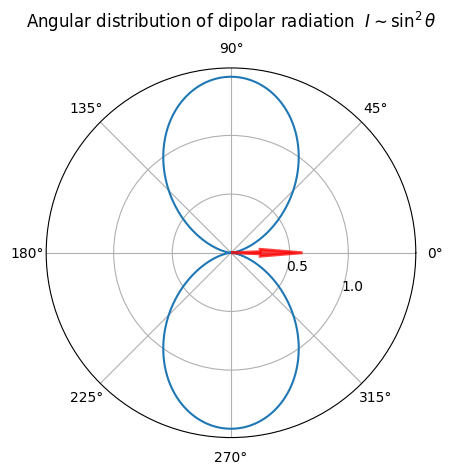

In [2]:
import matplotlib.pyplot as plt
import numpy as np
theta = np.arange(0, 2*np.pi, 0.005)
r = 1.5*np.sin(theta)**2
# 
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, r)
ax.set_rmax(2)
ax.set_rticks([0.5, 1])  # Less radial ticks
ax.set_rlabel_position(-20)  # Move radial labels away from plotted line
ax.grid(True)
ax.set_title(r'Angular distribution of dipolar radiation  $I \sim \sin^2\theta$', va='bottom')
arr1 = plt.arrow(0, 0, 0, 1/4, alpha = 0.75, width = 0.08,
edgecolor = 'red', facecolor = 'red', lw = 2, zorder = 5)
plt.show()

\begin{equation}
 I = \int \mathbf{S}\cdot \mathbf{n}\, dS = \frac{2\,\omega^{4}}{3\,c^{3}}\left|\,\mathbf{d}_{\omega}\,\right|^{2} = \frac{2}{3\,c^3}\,|\ddot{\mathbf{d}}|^2\,.
\end{equation}
<!--  -->
Середнє значення за період коливання, таким чином:
\begin{equation}
 \langle I\rangle  = \frac{\omega^{4}}{3\,c^3}\,d_0^2\,.
\end{equation}
<!--  -->
звісно припускається, що потужність випромінювання мала так що зміною енергії осцилятора можна знехтувати. В такому наближенні втрати енегії через випромінювання можна врахувати через введення сили "радіаційного тертя" в рівняння осцилятора:
$$
\ddot{x} = - \omega_0^2\,x - \gamma\,\dot{x}\,,\,\,\,\gamma = \frac{2\,e^2\omega^{2}}{3\,m\,c^3}
$$
Дійсно для середніх за період втрат енергії маємо:
$$
\frac{d E}{d t} = -\gamma\,E \,,\,\,\,\,E = m\frac{\dot{x}^2}{2}+m\omega^2\,\frac{x^2}{2}
$$
$$
\Omega^2-\omega^2_0-i\,\gamma\,\Omega = 0 \Rightarrow \Omega =\frac{i\,\gamma}{2}\pm \sqrt{\omega^2_0- \frac{\gamma^2}{4}} 
$$
Амплітуда коливань $x_{\omega}$:
$$
x_{\omega} = \int x(t)\,e^{-i\omega\,t}\,dt = i\,\frac{x_0}{\omega - \Omega}
$$
Так що інтенсивність випромінювання:
$$
I_{\omega}\sim |x_{\omega}|^2  = I_{0}\frac{\omega^2_0}{\gamma^2/4 + \left(\sqrt{\omega^2_0- \frac{\gamma^2}{4}}-\omega\right)^2}
$$
В результаті радіаційного тертя спектральні лінії припиняють відповідати монохроматичному переходу і розширюються.

In [3]:
from ipywidgets import interactive
def int(gamma=0.1):
    xc=np.linspace(0,5,500)
    yc=[((gamma/2)**2/((gamma/2)**2+(x-np.sqrt(1-(gamma/2)**2))**2)) for x in xc]
    plt.title('Intensity')
    plt.xlabel(r"$\omega/\omega_0$")
    plt.plot(xc,yc)
# 
interactive_plot = interactive(int, gamma=(1/100, 1/2))
#output = interactive_plot.children[-1]
#output.layout.height = '500px'
interactive_plot

interactive(children=(FloatSlider(value=0.1, description='gamma', max=0.5, min=0.01), Output()), _dom_classes=…

## Випромінювання і поглинання світла квантовою системою. Спонтанне і вимушене випромінювання.
<!--  -->
Застосуємо результати, які були отримані вище, у випадку взаємодії
квантової системи і ЕМП. При цьому ми будемо нехтувати релятивістськими ефектами (в тому числі запізнення і спін - магнітним взаємодіями). Вважаючи ЕМП поле слабким, гамільтоніан може
бути представлений у вигляді:
$$
H = H_{p} + H_{em} + U_{int}
$$
де $H_{p} $ - гамільтоніан частинки, $H_{em} $ - гамільтоніан вільного ЕМП, $U_{int}$ - взаємодія атом-ЕМП. Остання, загалом, є дуже складною, але у т.з. однофотонному наближенні її можна представити у вигляді ряду за безрозмірним параметром $\varepsilon = a_{B}/\lambda$. Нульове наближення $\varepsilon^0\sim 1$ еквівалентне поляризації атома під дією однорідного електричного поля (довгохвильове наближення), тобто виникає взаємодія ЕМП із дипольним моментом атому. Відповідні переходи під дією такої взаємодії називаються електричними дипольними переходами. Взагалі переходи між станами відбуваються з виконанням законів збереження фізичних величин які відповідають симетріям системи. Для системи атом+ЕМП має місце закон збереження енергії (однорідність часу) та закон збереження повного моменту імпульсу $\mathbf{J}$ (ізотропність напрямків). Також електромагнітна взаємодія зберігає просторову парність $P$ системи (симетрія право-ліво). Зміна стану атомну полягає в зміні відповідних квантових чисел $n,L,M,M_s$ у електронної системи (взаємодія ЕМП з ядром відповідає випромінюванню та поглинанню $\gamma$-квантів значно більшої енергії $MeV$) так що відбувається випромінювання (одного чи декількох) квантів ЕМП відповідної енергії, повного моменту імпульсу та просторово\ парності . При електричних дипольних переходах відбувається зміна квантового числа $\Delta l = \pm 1\,,\,\, \Delta m = \pm 1, 0$ у зв'язку з векторним характером оператора дипольного моменту, що відповідає $l=1$. Парність атомного стану $(-1)^{l}$. Відповідна парність фотону $P = -1$. Це називається правила відбору станів для електричного дипольного випромінювання. В наступному лінійному наближенні $\varepsilon$ атом взаємодіє із неоднорідним ЕМП полем, що відповідає наступним доданкам мультипольного розкладу: електричному квадрупольному та магніто-дипольному. Електрична квадрупольна взаємодія має $l=2$, відповідні правила відбору:
<!--  -->
\begin{align}
 l_{f} =& \left\{
 {\begin{array}{l}
 {\{l_{\,i} \pm 2\,,\,l_{\,i} \},l_{\,i} \ne 0} \\
 {2,    l_{\,i} = 0} \\
 \end{array}}\right.\notag\\
 m_{f} =& \{m_{i} \pm 2\,,m_{i} \pm 1\,,\,m_{\,i} \}\label{izeq13}
\end{align}
<!--  -->
парність фотона для такого переходу  $P = +1$. Загалом, можна показати, що у порядку $\varepsilon^{j-1}$ електричні $j$-мультипольні та $(j-1)$-магнітні переходи з випромінюванням фотонів з відповідим моментом імпульсу та парністю. Інтенсивність таких переходів зменшується з порядком, наібільш інтенсивними є дипольні переходи. Такі переходи і спостерігаються як спектральні лінії (випромінювання або поглинання). Врахування ефектів типу гальмування випромінюванням розглянутого вище призводить до того що атом перебуває в середньому час $1/\gamma$ у збудженному стані ($10^{-8} - 10^{-9} s$).

## Вивід закону Планка
Отримані вище результати можна застосувати до задачі про спектр рівноважного теплового випромінювання. Зрозуміло, що в рівновазі кількість переходів поглинання дорівнює кількості переходів випромінювання для кожного переходу $m\leftrightarrow n\,, E_{m}<E_{n}$. Кількість переходів в одиницю часу між станами $m \leftrightarrow n$  дорівнює $W_{mn} = I_{\omega_{mn}}/(\hbar\,\omega_{mn})$. Нехай кількість атомів у відповідних станах $N^{(a)}_{m}, N^{(a)}_{n}$ (принцип детального балансу):
$$
N^{(a)}_{n} W_{n \to m}^{(+)} = N^{(a)}_{m} W_{m \to n}^{(-)}
$$
який полягає в тому що в рівновазі кількість в одиницю часу атомних переходів випромінювання та поглинання між будь якими станами однакова. 

Інтенсивність переходів залежить від енергетичної густини випромінювання $\rho(\omega_{mn})$ причому інтенсивність випромінювання містить дві частини - __вимушене__ (пропорційне до $\rho(\omega_{mn})$) і __спонтанне випромінювання__, яке не залежить від $\rho(\omega_{mn})$: 
Вводячи коефіцієнти Айнштайна:
$$
W_{m \to n}^{(-)} = B_{m,n}\,\rho(\omega_{mn})\,,
W_{n \to m}^{(+)} = B_{m,n}\,\rho(\omega_{mn}) + A_{mn}\\
$$
Тоді
$$
N^{(a)}_{n} \left(B_{m,n}\,\rho(\omega_{mn}) + A_{mn}\right) = N^{(a)}_{m} B_{m,n}\,\rho(\omega_{mn}) \Rightarrow 
\rho(\omega_{mn}) = \frac{A_{mn}}{B_{m,n}}\frac{1}{\frac{N^{(a)}_m}{N^{(a)}_n} - 1}
$$
Приймаючи до уваги, що в рівновазі розподіл атомів за енергією це розподіл Больцмана $N^{(a)}_n = N_0\,e^{-\frac{E_n}{T}}$ отримаємо:
$$
\rho(\omega_{mn}) = \frac{A_{mn}}{B_{m,n}}\frac{1}{e^{\frac{E_n-E_m}{T}} - 1}
$$
Відношення $\frac{A_{mn}}{B_{m,n}}$ визначається з відповідності до класичної асимптотикі - закону Релея-Джинса:
$$
\frac{A_{mn}}{B_{m,n}} = \frac{\hbar\,\omega^3}{\pi^2\,c^3}
$$
В результаті остаточно приходимо до формули Планка:
$$
 \rho(\omega) = \frac{\hbar\,\omega^3}{\pi^2\,c^3}\,\frac{1}{e^{\frac{\hbar\,\omega}{T}} - 1}
$$
Як бачимо саме наявність спонтаного випромінювання ($A\ne 0 \leftrightarrow \hbar \ne 0!$) забезпечує нетривіальний рівноважний розподіл енергії теплового випромімінювання. Без врахування цього ефекту рівноважний стан відповідав тому що всі б атоми знаходились у основному стані і $\rho(\omega_{mn}) = 0$ і ніякого обміну енергії з випромінюванням не було (аналог ультрафіолетовій катастрофи). Завдяки спонтанному випромінюванню працють лазери ([LASER = Light Amplification by Stimulated Emission of Radiation](https://en.wikipedia.org/wiki/Laser))